## Dog breeds classifier.
In this tasks you are supposed to build dog breeds classifier.
You may use materials of previous classes, chat gpt, anything.

Just get the maximum accuracy.

In [1]:
from glob import glob
import os
import numpy as np
np.bool=bool
import cv2
import matplotlib.pyplot as plt
import pickle as pkl
import uuid
from time import time
import torchvision.transforms.functional as F

### Download the data

In [3]:
# Google golab or in any Unix OS you may do that:
#!wget -O dogdata.zip https://www.dropbox.com/scl/fi/bokia8qstdekcyjqig1c5/dogdata.zip?rlkey=esrxurxfr4fe50duknmab979a&st=aqjo6u4r&dl=1 
#№!unzip -q dogdata.zip -d dogdata
#data_path = './dogdata'
# Or, you may download and extract file manually: https://www.dropbox.com/scl/fi/bokia8qstdekcyjqig1c5/dogdata.zip
# And provide the path to extracted data here:
data_path = 'D:/Data/dogs'

In [68]:
from sklearn.model_selection import train_test_split

### Read labels and filenames

In [194]:
fns = []
y = []
for lp in glob(f'{data_path}/train/*'):
    label = os.path.basename(lp)
    for fn in glob(f'{lp}/*'):
        fns.append(fn)
        y.append(label)
fns = np.array(fns)


labels = sorted(list(set(y)))
label_map = {k: v for v, k in enumerate(labels)}
y = [label_map[v] for v in y]
y = np.array(y)

fns, fns_val, y, y_val = train_test_split(fns, y, test_size=0.05, random_state=42, stratify=y)

fns_submit = glob(f'{data_path}/test/*')

### Here are several examples:

0


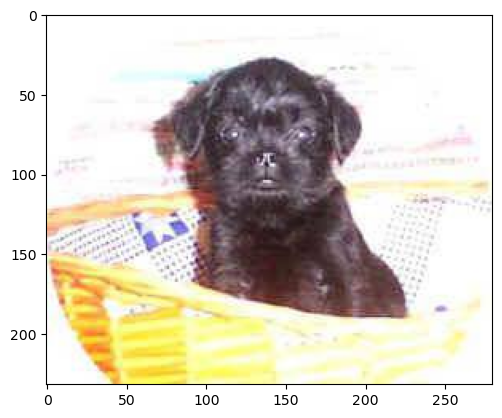

1


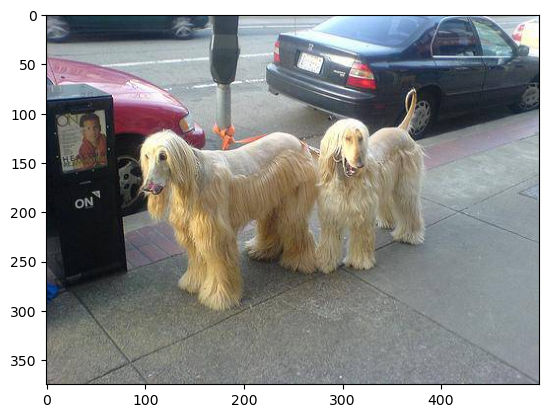

2


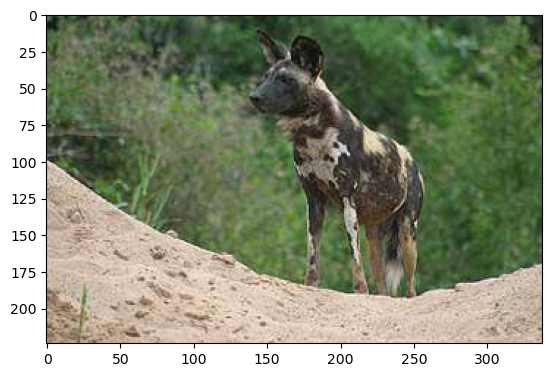

3


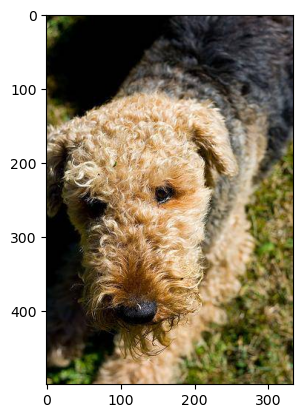

4


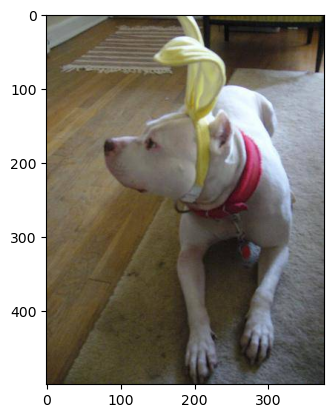

In [199]:
for label in list(set(y))[:5]:
    print(label)
    img = cv2.imread(fns[y == label][0])
    plt.imshow(img[:,:,::-1])
    plt.show()

# Your code goes here:

In [325]:
import imgaug.augmenters as iaa
import torch
from torchvision import transforms
import numpy as np
from PIL import Image

class SquarePad:
    """Паддинг до квадратного размера с сохранением пропорций"""
    def __init__(self, background_color=0):
        self.background_color = background_color

    def __call__(self, image):
        w, h = image.size
        max_wh = max(w, h)
        hp = (max_wh - w) // 2
        vp = (max_wh - h) // 2
        padding = (hp, vp, max_wh - w - hp, max_wh - h - vp)
        return F.pad(image, padding, self.background_color, 'constant')

class DogDataset(torch.utils.data.Dataset):
    def __init__(self, image_paths, labels, transform=None):
        self.image_paths = image_paths
        self.imgs = [Image.open(pth).convert('RGB') for pth in tqdm(self.image_paths)]
        print('Dataset read')
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image = self.imgs[idx]
        label = self.labels[idx]

        if self.transform:
            image = self.transform(image)

        return image, label

S = 256
# Аугментации для тренировочных данных
train_augmentations = transforms.Compose([
    SquarePad(),
    transforms.Resize((S, S)),
    transforms.ToTensor(),  # Конвертируем в тензор (0-1)
    transforms.Lambda(lambda x: (x * 255).byte()),  # в uint8 для imgaug
    transforms.Lambda(lambda x: x.permute(1, 2, 0).numpy()),  # HWC для imgaug
    transforms.Lambda(lambda x: iaa.Sequential([
        # Геометрические преобразования
        iaa.Affine(
            rotate=(-15, 15),
            translate_percent=(-0.1, 0.1),
            scale=(0.9, 1.1),
            shear=(-8, 8)
        ),

        # Цветовые преобразования
        iaa.SomeOf((0, 2), [
            iaa.MultiplyBrightness((0.8, 1.2)),
            iaa.AddToHueAndSaturation((-20, 20)),
            iaa.LinearContrast((0.8, 1.2)),
            iaa.GammaContrast((0.8, 1.2))
        ]),

        # Размытия и шумы
        iaa.Sometimes(0.75,
            iaa.SomeOf((0, 2), [
                iaa.GaussianBlur(sigma=(0, 0.01)),
                iaa.MotionBlur(k=3),
                iaa.AdditiveGaussianNoise(scale=(0, 0.02*255))
            ]),
        ),

        # Пространственные преобразования
        iaa.Sometimes(0.3, iaa.CropAndPad(percent=(-0.1, 0.1))),
        iaa.Sometimes(0.1, iaa.CoarseDropout(0.02, size_percent=0.3)),

        # Улучшение резкости
        iaa.Sometimes(0.2, iaa.Sharpen(alpha=(0, 0.3), lightness=(0.8, 1.2)))
    ]).augment_image(x)),
    transforms.Lambda(lambda x: torch.from_numpy(x).permute(2, 0, 1).float() / 255.0),  # Возврат к CHW
    #transforms.Resize((S, S)),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # ImageNet stats
])

# Аугментации для валидации (только базовые преобразования)
val_augmentations = transforms.Compose([
    SquarePad(),
    transforms.Resize((S, S)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

#train_d = DogDataset(fns, y, train_augmentations)
val_d = DogDataset(fns_val, y_val, val_augmentations)

100%|████████████████████████████████████████████████████████████████████████████████| 452/452 [00:07<00:00, 56.77it/s]

Dataset read


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-4.053115898461357e-09..0.913725456237793].


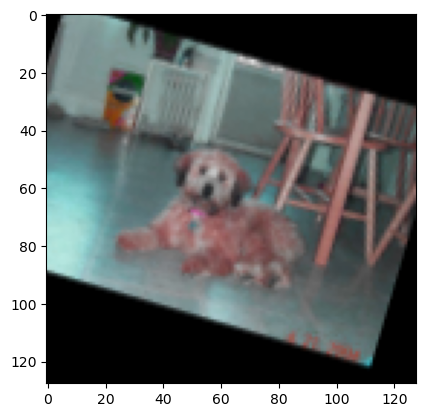

In [260]:
plt.imshow((train_d[5][0].numpy().transpose(1, 2, 0) * [0.229, 0.224, 0.225] + [0.485, 0.456, 0.406]))

In [327]:
import torchvision
from torchsummary import summary

model_resnet18 = torchvision.models.resnet18(pretrained=True)
model_resnet18.fc = torch.nn.Sequential(torch.nn.BatchNorm1d(512), torch.nn.Dropout(0.9), torch.nn.Linear(512, 256), torch.nn.ReLU(), torch.nn.BatchNorm1d(256), torch.nn.Dropout(0.9), torch.nn.Linear(256, 120))
model = model_resnet18

for p in model.parameters():
    p.requires_grad = False
for p in model.fc.parameters():
    p.requires_grad = True
for p in model.layer4[1].parameters():
    p.requires_grad = True

summary(model, train_d[0][0].shape, device="cpu")

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 64, 64]           9,408
       BatchNorm2d-2           [-1, 64, 64, 64]             128
              ReLU-3           [-1, 64, 64, 64]               0
         MaxPool2d-4           [-1, 64, 32, 32]               0
            Conv2d-5           [-1, 64, 32, 32]          36,864
       BatchNorm2d-6           [-1, 64, 32, 32]             128
              ReLU-7           [-1, 64, 32, 32]               0
            Conv2d-8           [-1, 64, 32, 32]          36,864
       BatchNorm2d-9           [-1, 64, 32, 32]             128
             ReLU-10           [-1, 64, 32, 32]               0
       BasicBlock-11           [-1, 64, 32, 32]               0
           Conv2d-12           [-1, 64, 32, 32]          36,864
      BatchNorm2d-13           [-1, 64, 32, 32]             128
             ReLU-14           [-1, 64,

In [310]:
def train_one_step(model, optimizer, criterion, inputs, labels):
    optimizer.zero_grad()
    out = model(inputs)
    loss = criterion(out, labels)
    loss.backward()
    optimizer.step()
    return loss.item()

In [312]:
from torch.utils.data import DataLoader

In [315]:
train_loader = DataLoader(train_d, shuffle=True, batch_size=32)
val_loader = DataLoader(val_d, shuffle=False, batch_size=32)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
criterion = torch.nn.CrossEntropyLoss().to(device)
optimizer = torch.optim.Adam(model.parameters())

In [274]:
l = iter(train_loader)
dd = next(l)

In [290]:
from tqdm import tqdm

In [316]:
@torch.no_grad()
def evaluate_model(model, dataloader, device, caption=""):
    model.eval()
    correct = 0
    total = 0
    loss = 0.0
    for images, labels in tqdm(dataloader, disable=True):
        yy = torch.nn.functional.one_hot(labels.long(), num_classes=120).float().to(device)
        outputs = model(images.to(device))
        loss += criterion(outputs, yy)
        _, predicted = torch.max(outputs.cpu().data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
    eps = 1e-9
    accuracy = correct / (total + eps)
    loss = (loss / (total + eps)).item()
    print(f"Acc = {accuracy:.4f}, loss = {loss:.5f}")
    return accuracy, loss

In [319]:
loss_history = []
loss_test_history = []

100%|████████████████████████████████████████████████████████████████████████████████| 268/268 [04:39<00:00,  1.04s/it]


Epoch: 1, loss = 5.6400
Acc = 0.0133, loss = 0.18435


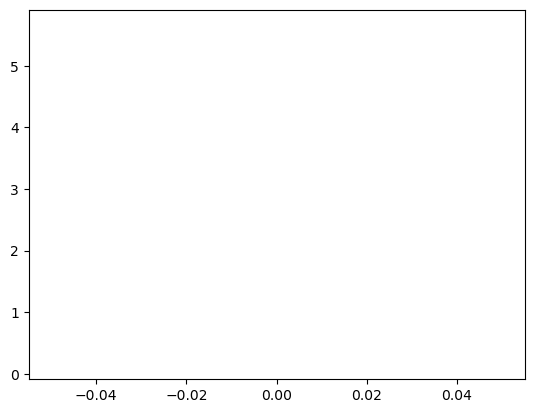

100%|████████████████████████████████████████████████████████████████████████████████| 268/268 [02:23<00:00,  1.86it/s]


Epoch: 2, loss = 4.7991
Acc = 0.0111, loss = 0.15857


100%|████████████████████████████████████████████████████████████████████████████████| 268/268 [02:24<00:00,  1.85it/s]


Epoch: 3, loss = 4.7879
Acc = 0.0133, loss = 0.15869


100%|████████████████████████████████████████████████████████████████████████████████| 268/268 [02:35<00:00,  1.73it/s]


Epoch: 4, loss = 4.7827
Acc = 0.0155, loss = 0.15855


... (10 outputs left out)

100%|████████████████████████████████████████████████████████████████████████████████| 268/268 [02:29<00:00,  1.80it/s]


Epoch: 10, loss = 4.6475
Acc = 0.0111, loss = 0.15581


100%|████████████████████████████████████████████████████████████████████████████████| 268/268 [02:28<00:00,  1.80it/s]


Epoch: 11, loss = 4.5782
Acc = 0.0199, loss = 0.15238


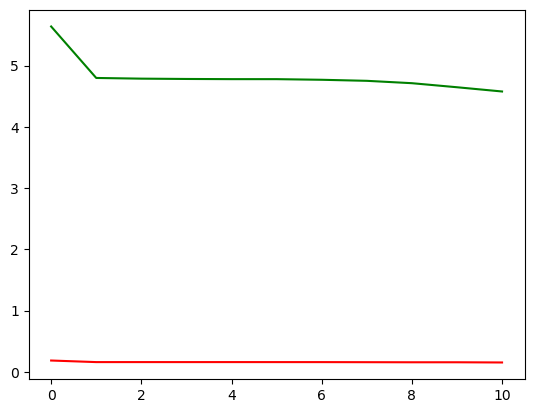

100%|████████████████████████████████████████████████████████████████████████████████| 268/268 [02:28<00:00,  1.80it/s]


Epoch: 12, loss = 4.4991
Acc = 0.0376, loss = 0.14866


100%|████████████████████████████████████████████████████████████████████████████████| 268/268 [02:28<00:00,  1.80it/s]


Epoch: 13, loss = 4.4098
Acc = 0.0354, loss = 0.14824


100%|████████████████████████████████████████████████████████████████████████████████| 268/268 [02:31<00:00,  1.77it/s]


Epoch: 14, loss = 4.3220
Acc = 0.0310, loss = 0.14759


... (10 outputs left out)

100%|████████████████████████████████████████████████████████████████████████████████| 268/268 [02:31<00:00,  1.77it/s]


Epoch: 20, loss = 3.7867
Acc = 0.0686, loss = 0.13387


100%|████████████████████████████████████████████████████████████████████████████████| 268/268 [02:29<00:00,  1.79it/s]


Epoch: 21, loss = 3.7161
Acc = 0.0973, loss = 0.12883


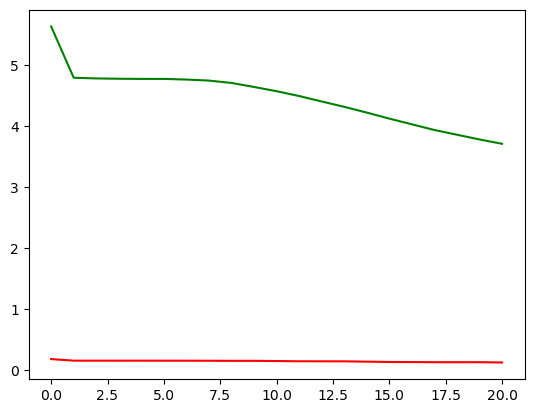

100%|████████████████████████████████████████████████████████████████████████████████| 268/268 [02:30<00:00,  1.78it/s]


Epoch: 22, loss = 3.6309
Acc = 0.0929, loss = 0.12728


100%|████████████████████████████████████████████████████████████████████████████████| 268/268 [02:33<00:00,  1.75it/s]


Epoch: 23, loss = 3.5651
Acc = 0.1062, loss = 0.12964


100%|████████████████████████████████████████████████████████████████████████████████| 268/268 [02:28<00:00,  1.80it/s]


Epoch: 24, loss = 3.4837
Acc = 0.0951, loss = 0.13284


... (10 outputs left out)

100%|████████████████████████████████████████████████████████████████████████████████| 268/268 [02:37<00:00,  1.70it/s]


Epoch: 30, loss = 2.9808
Acc = 0.0996, loss = 0.13344


100%|████████████████████████████████████████████████████████████████████████████████| 268/268 [02:34<00:00,  1.73it/s]


Epoch: 31, loss = 2.8808
Acc = 0.1106, loss = 0.13408


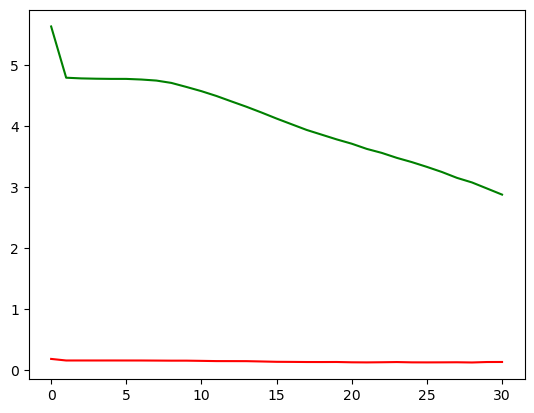

  8%|██████▋                                                                          | 22/268 [00:12<02:17,  1.79it/s]


KeyboardInterrupt: 

In [323]:
model.train()
for epoch in range(100):
    epoch_loss = 0.0
    n_imgs = 0
    for inputs, labels in tqdm(train_loader):
        yy = torch.nn.functional.one_hot(labels.long(), num_classes=120).float()
        inputs, labels = inputs.to(device), yy.to(device)
        batch_loss = train_one_step(model, optimizer, criterion, inputs, labels)
        n_imgs += 1
        epoch_loss += batch_loss
    epoch_loss /= n_imgs
    print("Epoch: {}, loss = {:.4f}".format(epoch + 1, epoch_loss))
    loss_history.append(epoch_loss)
    acc, tloss = evaluate_model(model, val_loader, 'cuda')
    loss_test_history.append(tloss)
    if epoch % 10 == 0:
      plt.plot(loss_history, color='green')
      plt.plot(loss_test_history, color='red')
      plt.show()

In [302]:
@torch.no_grad()
def evaluate_model(model, dataloader, device, caption=""):
    model.eval()
    correct = 0
    total = 0
    for data in tqdm(dataloader):
        images, labels = data
        outputs = model(images.to(device))
        _, predicted = torch.max(outputs.cpu().data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
    eps = 1e-9
    accuracy = correct / (total + eps)
    print(f"Acc = {accuracy:.4f}")

In [304]:
evaluate_model(model, val_loader, 'cuda')

100%|██████████████████████████████████████████████████████████████████████████████████| 15/15 [00:13<00:00,  1.13it/s]

Acc = 0.1814


## Generating the answer to submit:

In [ ]:
# This code does not work.
# You may rewrite it as you wish (e.g. use torch.utils.data.Dataset and proper data preprocessing (like ToTensor())).
# It just shows that you should read images at filenames given in fns_submit and accumulate predicted labels in y_submit
y_submit = []
for fn in fns_submit:
    img = cv2.imread(fn)
    label = model(transform(img))
    y_submit.append(label)

In [ ]:
answer_to_submit = {fn: label for fn, label in zip(fns_submit, y_submit)}
with open('my_answer_dogs.pkl', 'wb') as f:
    pkl.dump((answer_to_submit, uuid.uuid4().hex, time()), f)

Now submit your result to yandex contest and let us see the score.